<a href="https://colab.research.google.com/github/marwan1265/MRI_CNN/blob/main/MRI_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub
import matplotlib.pyplot as plt
import cv2
import numpy as np
import os

path = kagglehub.dataset_download("navoneel/brain-mri-images-for-brain-tumor-detection")

Using Colab cache for faster access to the 'brain-mri-images-for-brain-tumor-detection' dataset.


In [ ]:


# Define image dimensions (already in kernel state, but re-defining for clarity)
IMG_HEIGHT = 150
IMG_WIDTH = 150

# Create empty lists to store processed images and labels
data = []
labels = []

# Define categories and their corresponding numerical labels (already in kernel state)
categories = {'no': 0, 'yes': 1}

# Base path for the dataset (already in kernel state)
base_path = '/kaggle/input/brain-mri-images-for-brain-tumor-detection'

# Iterate through categories to load and process images
for category_name, label in categories.items():
    category_path = os.path.join(base_path, category_name)
    print(f"Processing category: {category_name}")

    # List all files in the category directory
    for img_name in os.listdir(category_path):
        # Filter for image files
        if img_name.lower().endswith(('.jpg', '.jpeg', '.png')):
            img_path = os.path.join(category_path, img_name)
            try:
                # Read the image
                img = cv2.imread(img_path)
                if img is None:
                    print(f"Warning: Could not read image {img_path}. Skipping.")
                    continue

                # Resize the image to consistent dimensions
                img = cv2.resize(img, (IMG_WIDTH, IMG_HEIGHT))

                # Convert to NumPy array and normalize pixel values
                img = np.array(img) / 255.0

                # Append to data and labels lists
                data.append(img)
                labels.append(label)
            except Exception as e:
                print(f"Error processing image {img_path}: {e}. Skipping.")

# Convert data and labels lists to NumPy arrays
X = np.array(data)
y = np.array(labels)

print("Image data loading and preprocessing complete.")
print(f"Shape of X (images): {X.shape}")
print(f"Shape of y (labels): {y.shape}")

Processing category: no
Processing category: yes
Image data loading and preprocessing complete.
Shape of X (images): (253, 150, 150, 3)
Shape of y (labels): (253,)


In [ ]:
from sklearn.model_selection import train_test_split

# Split the data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of X_val: {X_val.shape}")
print(f"Shape of y_val: {y_val.shape}")

Shape of X_train: (202, 150, 150, 3)
Shape of y_train: (202,)
Shape of X_val: (51, 150, 150, 3)
Shape of y_val: (51,)


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Define the CNN model architecture
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        # First convolutional layer
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Second convolutional layer
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)

        # Calculate the size of the flattened features after conv and pooling layers
        # Input image size: 150x150
        # After conv1 (150x150) -> pool (75x75)
        # After conv2 (75x75) -> pool (37x37, or 38x38 if 75/2 rounds up for odd sizes, but common practice rounds down or handles explicitly. Let's assume 37x37 based on integer division for MaxPool)
        # Output channels from conv2 are 64
        self.fc1_input_features = 64 * (150 // 2 // 2) * (150 // 2 // 2) # 64 * 37 * 37 = 87616

        # Fully connected layers
        self.fc1 = nn.Linear(self.fc1_input_features, 512)
        self.fc2 = nn.Linear(512, 1)  # Output a single value for binary classification

    def forward(self, x):
        # Conv -> ReLU -> Pool
        x = self.pool(F.relu(self.conv1(x)))
        # Conv -> ReLU -> Pool
        x = self.pool(F.relu(self.conv2(x)))

        # Flatten the output for the fully connected layer
        x = x.view(-1, self.fc1_input_features)

        # Fully connected layers with ReLU activation
        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        # Sigmoid activation for binary classification output (probability)
        return torch.sigmoid(x)

# Instantiate the model
model = SimpleCNN()

# Print the model architecture
print(model)

# To verify the calculated input features for fc1, we can pass a dummy tensor
# A dummy tensor of shape (batch_size, channels, height, width)
# input_tensor = torch.randn(1, 3, IMG_HEIGHT, IMG_WIDTH)
# output_from_conv_layers = model.pool(F.relu(model.conv2(model.pool(F.relu(model.conv1(input_tensor))))))
# print(f"Shape after conv/pool layers: {output_from_conv_layers.shape}")
# print(f"Calculated fc1_input_features: {model.fc1_input_features}")

SimpleCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=87616, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=1, bias=True)
)


In [ ]:
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# ... (Previous tensor conversion code remains the same) ...
X_train_tensor = torch.from_numpy(X_train).float().permute(0, 3, 1, 2)
y_train_tensor = torch.from_numpy(y_train).float().unsqueeze(1)
X_val_tensor = torch.from_numpy(X_val).float().permute(0, 3, 1, 2)
y_val_tensor = torch.from_numpy(y_val).float().unsqueeze(1)

criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 10
batch_size = 32

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

print("Starting model training...")

# 1. Initialize lists
train_losses = []
val_losses = []
train_accs = []
val_accs = []

# 2. Training Loop
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for i, (inputs, labels) in enumerate(train_loader):
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        predicted = (outputs > 0.5).float()
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total_train
    epoch_train_accuracy = correct_train / total_train

    train_losses.append(epoch_train_loss)
    train_accs.append(epoch_train_accuracy)

    # Validation step
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for inputs_val, labels_val in val_loader:
            outputs_val = model(inputs_val)
            loss_val = criterion(outputs_val, labels_val)

            val_loss += loss_val.item() * inputs_val.size(0)
            predicted_val = (outputs_val > 0.5).float()
            total_val += labels_val.size(0)
            correct_val += (predicted_val == labels_val).sum().item()

    epoch_val_loss = val_loss / total_val
    epoch_val_accuracy = correct_val / total_val

    val_losses.append(epoch_val_loss)
    val_accs.append(epoch_val_accuracy)

    print(f"Epoch {epoch+1}/{num_epochs}: Train Loss: {epoch_train_loss:.4f}, Val Loss: {epoch_val_loss:.4f}")

print("Training complete.")

Starting model training...
Epoch 1/10: Train Loss: 2.3481, Val Loss: 0.6687
Epoch 2/10: Train Loss: 0.6577, Val Loss: 0.6432
Epoch 3/10: Train Loss: 0.5772, Val Loss: 0.4252
Epoch 4/10: Train Loss: 0.5363, Val Loss: 0.4569
Epoch 5/10: Train Loss: 0.4787, Val Loss: 0.5419
Epoch 6/10: Train Loss: 0.4035, Val Loss: 0.3463
Epoch 7/10: Train Loss: 0.3321, Val Loss: 0.3526
Epoch 8/10: Train Loss: 0.2412, Val Loss: 0.4505
Epoch 9/10: Train Loss: 0.2472, Val Loss: 0.3624
Epoch 10/10: Train Loss: 0.1627, Val Loss: 0.4353
Training complete.


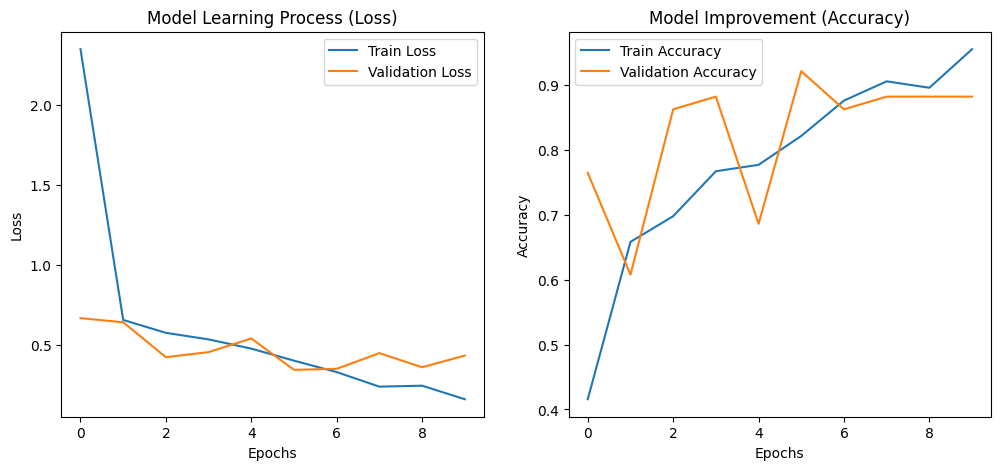

In [ ]:
# Plotting code
plt.figure(figsize=(12, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Model Learning Process (Loss)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train Accuracy')
plt.plot(val_accs, label='Validation Accuracy')
plt.title('Model Improvement (Accuracy)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

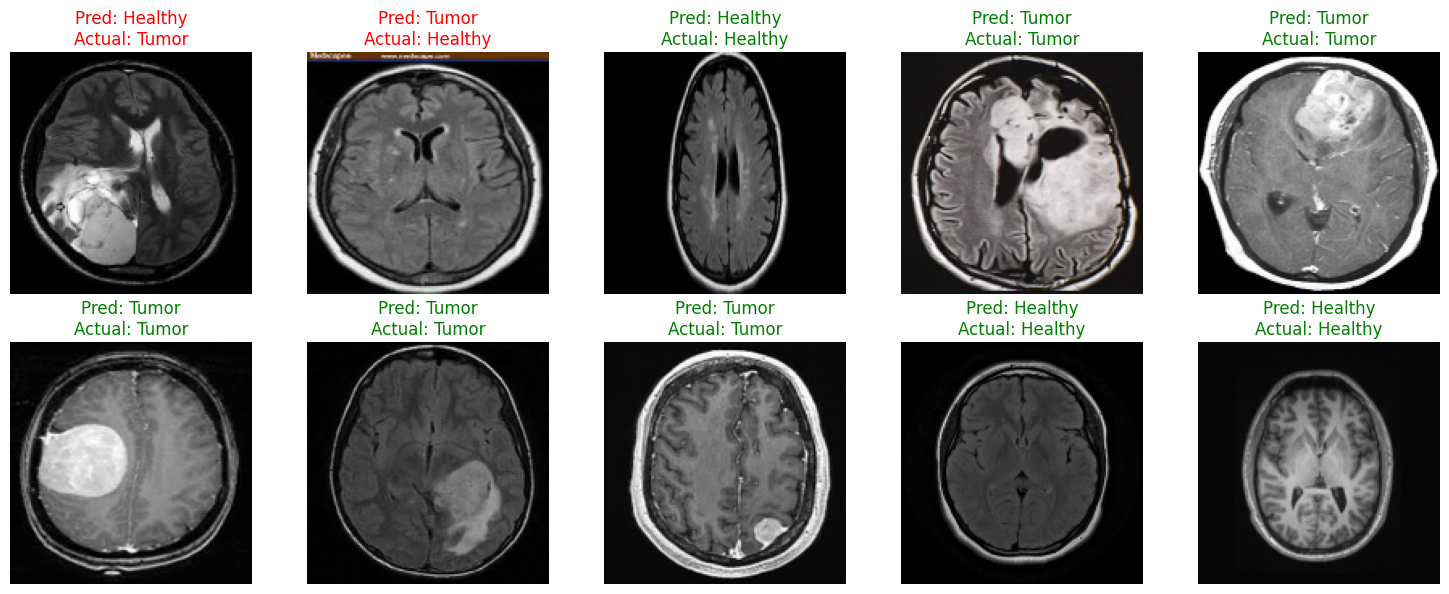

In [ ]:
# Visualize Predictions (The Artefact)
def visualize_predictions(model, loader, num_images=10):
    model.eval()
    images_shown = 0
    plt.figure(figsize=(15, 6))

    with torch.no_grad():
        for inputs, labels in loader:
            outputs = model(inputs)
            predictions = (outputs > 0.5).float()

            for i in range(inputs.size(0)):
                if images_shown >= num_images:
                    break

                # Convert tensor back to image format for display
                img = inputs[i].permute(1, 2, 0).numpy()

                # Get prediction and actual label
                pred_label = "Tumor" if predictions[i].item() == 1 else "Healthy"
                actual_label = "Tumor" if labels[i].item() == 1 else "Healthy"

                # Color code: Green if correct, Red if wrong
                color = 'green' if pred_label == actual_label else 'red'

                plt.subplot(2, 5, images_shown + 1)
                plt.imshow(img, cmap='gray')
                plt.title(f"Pred: {pred_label}\nActual: {actual_label}", color=color)
                plt.axis('off')

                images_shown += 1

            if images_shown >= num_images:
                break
    plt.tight_layout()
    plt.show()

visualize_predictions(model, val_loader)